# Solar filament instance segmentation: the full pipeline

This notebook runs our final pipeline (`configs/final.yaml`, submission `y4_v2_t60_s`, public leaderboard 0.40) on the
180 MAGFiLO H-alpha test frames, from the weights stored in `weights/`. Nothing is retrained. The result is checked
against the file we submitted (`reference/submission_final.csv`).

```
frame (2048², 8-bit)
 ├─► 1024², per-image percentile scaling
 │    ├─► 5 × ConvNeXt-T U-Net, 8 views ─────────► base map (per fold, and their mean)
 │    └─► 5 × ResNet34 U-Net, 8 views ──────────► vote map (features only)
 │         └─► 5 × context U-Net (image + ConvNeXt map k + ResNet34 map k), 8 views ─► context map (features only)
 ├─► native 2048², same scaling
 │    └─► 5 × small-filament specialist, 8 views ─► specialist map (per fold, and their mean)
 └─► native 2048², 3 channels ─► 20 × YOLO26m-seg (4 seeds × 5 folds) ─► detector instances (features only)
fused map (base + specialist) / 2 ─► candidates: fg ≥ 0.4, area ≥ 150 px
candidates ─► 46 features + crop-CNN score ─► FZ verifier ─► u_FZ
           ─► nz1 outline of every candidate (expected-IoU level of the fused map)
           ─► + 6 context votes + 6 detector columns (on the nz1 outlines) ─► keep model (59 columns) ─► keep if u ≥ 0.25
           ─► refiner (5 networks, rotated native crops, per-fold fused maps) for every candidate with u_FZ ≥ 0.10
kept candidates ─► u_FZ ≤ 0.55: refined probability shifted by (−0.23, +0.05) px, ≥ 0.60, connected to the outline
                ─► otherwise: the nz1 outline re-cut from the fused map shifted by the same amount
                ─► overlaps resolved ─► disjoint instances ─► COCO RLE rows
```

Sections:
1. Setup and data
2. Preprocessing on one frame
3. Training (optional, off by default)
4. Inference on the test set → `outputs/submission_final.csv`, checked against the submitted file
5. What each stage does, on one test frame
6. Evaluation on held-out labelled frames: FZ_nz1 vs the final pipeline with single-fold models
7. Overlays

The two earlier pipelines the final one is built on (`configs/fz_nz1.yaml`, `configs/f_lite.yaml`) run the same way
with `python -m filament_seg --config ...`;
the README lists what each reproduces.

## 1. Setup and data

```bash
pip install -r requirements.txt            # pinned versions (CPU build of PyTorch; see the README for CUDA)
kaggle competitions download -c filament-segmentation-2026 -p data
unzip -q data/filament-segmentation-2026.zip -d data
# -> data/MAGFiLO_1.0_Kaggle_2026/{train,test}
```

The competition data is not part of this repository. To keep it elsewhere, set `FILAMENT_DATA_ROOT` to the folder
that contains `train/` and `test/`. `FILAMENT_DEMO_MAX_FRAMES=3` runs section 4 on three frames only.

In [1]:
import json, os, sys, time, platform, warnings
from pathlib import Path
warnings.filterwarnings('ignore', message='IProgress not found')  # tqdm notice triggered by importing timm

REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO))

import numpy as np
import matplotlib.pyplot as plt
import torch
from pycocotools import mask as cm

from filament_seg.config import load_config, data_path, resolve
from filament_seg.data import list_images, read_gray, model_input, normalize_image, load_ground_truth
from filament_seg.pipeline import Pipeline, predict_frames
from filament_seg.submission import write_submission, validate_submission, read_submission, sha256
from filament_seg.metrics import evaluate
from filament_seg import viz

plt.rcParams['figure.dpi'] = 80
cfg = load_config(REPO/'configs'/'final.yaml')
OUT = resolve(cfg['output']['dir']); OUT.mkdir(exist_ok=True)
test_paths = list_images(data_path(cfg, 'test_images'))
train_paths = list_images(data_path(cfg, 'train_images'))
print(f'test frames: {len(test_paths)}, labelled frames: {len(train_paths)}')
MAX_FRAMES = int(os.environ.get('FILAMENT_DEMO_MAX_FRAMES', 0)) or None
run_paths = dict(list(test_paths.items())[:MAX_FRAMES])
print(f'frames processed in this run: {len(run_paths)}')
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
print(f'python {platform.python_version()}, torch {torch.__version__}, device: {gpu or "cpu"}, '
      f'CPU threads: {torch.get_num_threads()}, logical CPUs: {os.cpu_count()}')

wdir = resolve(cfg['weights']['dir'])
manifest = json.loads((wdir/'manifest.json').read_text())
sizes = {f.name: f.stat().st_size/1e6 for f in wdir.iterdir()}
print(f'weights/: {len(sizes)} files, {sum(sizes.values()):.0f} MB, largest {max(sizes, key=sizes.get)} ({max(sizes.values()):.1f} MB)')
w = cfg['weights']
families = {'ConvNeXt segmenters': w['segmenters'], 'specialists': w['specialists'], 'ResNet34 voters': w['voters'],
            'context networks': w['context'], 'crop CNNs': w['crop_cnns'], 'YOLO detectors': w['detectors'],
            'refiners': w['refiners'], 'FZ verifier (GBM)': [w['gbm']], 'keep model (GBM)': [w['keep_gbm']]}
total = 0
for name, members in families.items():
    mb = sum(sizes[f] for m in members for f in manifest[m]['files'])
    total += mb
    print(f'  {name:20s}: {len(members):2d} × {manifest[members[0]]["architecture"].split(" (")[0][:60]:60s} {mb:6.0f} MB')
print(f'  final pipeline: {sum(len(m) for m in families.values())-2} networks + 2 GBMs, {total:.0f} MB')

test frames: 180, labelled frames: 707
frames processed in this run: 180
python 3.13.5, torch 2.11.0+cu128, device: NVIDIA GeForce RTX 5090, CPU threads: 16, logical CPUs: 32
weights/: 78 files, 3889 MB, largest r34_fold0.part1of2.safetensors (85.2 MB)
  ConvNeXt segmenters :  5 × ConvNeXtUNet                                                    639 MB
  specialists         :  5 × ConvNeXtUNet                                                    639 MB
  ResNet34 voters     :  5 × ResNet34UNet                                                    489 MB
  context networks    :  5 × ConvNeXtUNet                                                    320 MB
  crop CNNs           :  5 × CropVerifierCNN                                                 113 MB
  YOLO detectors      : 20 × Ultralytics YOLO26m-seg checkpoint                             1095 MB
  refiners            :  5 × RefineUNet                                                      321 MB
  FZ verifier (GBM)   :  1 × bagged sklearn His

## 2. Preprocessing on one frame

Inference uses only the test frame itself. The frame is converted to 8-bit grayscale and rescaled per image: the
1st/99th intensity percentiles inside a central disk (radius 0.45 of the frame) map to 0 and 1, values are clipped and
centred as (v − 0.5)/0.25. The 1024² networks see the frame resized with bilinear resampling; the specialists and the
refiners see native pixels. The detectors see the native 8-bit frame (three identical channels) and do their own
resizing to 1536. No dataset statistics, dates or metadata are used.

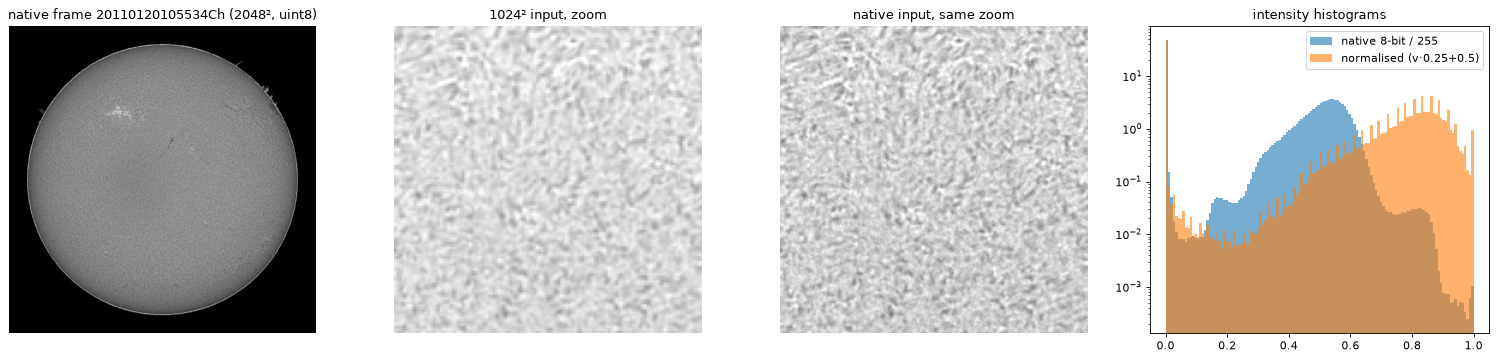

In [2]:
key = sorted(test_paths)[0]
gray = read_gray(test_paths[key])
x = model_input(test_paths[key], cfg['inference']['side'])
xn = normalize_image(gray)
crop = (slice(700, 956), slice(700, 956))
fig, ax = plt.subplots(1, 4, figsize=(19, 4.6))
ax[0].imshow(gray, cmap='gray'); ax[0].set_title(f'native frame {key} (2048², uint8)'); ax[0].axis('off')
ax[1].imshow(x[350:478, 350:478], cmap='gray', vmin=-2, vmax=2); ax[1].set_title('1024² input, zoom'); ax[1].axis('off')
ax[2].imshow(xn[crop], cmap='gray', vmin=-2, vmax=2); ax[2].set_title('native input, same zoom'); ax[2].axis('off')
ax[3].hist(gray.ravel()/255, 128, alpha=.6, density=True, label='native 8-bit / 255')
ax[3].hist(((x*.25)+.5).ravel(), 128, alpha=.6, density=True, label='normalised (v·0.25+0.5)')
ax[3].set_yscale('log'); ax[3].legend(); ax[3].set_title('intensity histograms')
plt.tight_layout(); plt.show()

## 3. Training (optional; not run by default)

The released weights were trained on GPUs with the scripts in `train/`; `train/README.md` lists every command, the
hardware and the run times. All 707 labelled frames are split into 5 calendar-month folds (`configs/folds_full.json`).
Fold *k*'s networks never saw fold *k*'s frames, so every later stage (verifier, context networks, keep model,
refiner) is trained on out-of-fold inputs, the kind of input it gets at test time. The cell below only prints the order
of the steps; `train/README.md` has the arguments.

In [3]:
RUN_TRAINING = False
steps = ['prepare_data.py            caches and per-annotator soft targets',
         'train_convnext_unet.py     5 ConvNeXt-T U-Nets (1024)',
         'train_r34_unet.py          5 ResNet34 U-Nets (1024)',
         'train_specialist.py        5 small-filament specialists (native crops)',
         'train_context_unet.py      5 context U-Nets on out-of-fold ConvNeXt + ResNet34 maps',
         'build_verifier_data.py     out-of-fold candidates, 46 features, targets, crops',
         'train_crop_cnn.py          5 crop CNNs',
         'train_gbm.py               FZ verifier (46 features + crop-CNN score)',
         'train_detector.py          20 YOLO26m-seg detectors (4 seeds x 5 folds)',
         'build_keep_columns.py      out-of-fold context votes and detector columns',
         'train_gbm.py --keep        keep model (59 columns)',
         'train_refiner.py           5 instance refiners (crop bank + truncation training)',
         'export_weights.py          weights/ + manifest.json']
for i, s in enumerate(steps, 1):
    print(f'{i:2d}. train/{s}')

 1. train/prepare_data.py            caches and per-annotator soft targets
 2. train/train_convnext_unet.py     5 ConvNeXt-T U-Nets (1024)
 3. train/train_r34_unet.py          5 ResNet34 U-Nets (1024)
 4. train/train_specialist.py        5 small-filament specialists (native crops)
 5. train/train_context_unet.py      5 context U-Nets on out-of-fold ConvNeXt + ResNet34 maps
 6. train/build_verifier_data.py     out-of-fold candidates, 46 features, targets, crops
 7. train/train_crop_cnn.py          5 crop CNNs
 8. train/train_gbm.py               FZ verifier (46 features + crop-CNN score)
 9. train/train_detector.py          20 YOLO26m-seg detectors (4 seeds x 5 folds)
10. train/build_keep_columns.py      out-of-fold context votes and detector columns
11. train/train_gbm.py --keep        keep model (59 columns)
12. train/train_refiner.py           5 instance refiners (crop bank + truncation training)
13. train/export_weights.py          weights/ + manifest.json


## 4. Inference on the test set → `submission_final.csv`

Every frame goes through all stages; results are cached per frame in `outputs/frames_y4_v2_t60_s/`, so an interrupted
run resumes. Each cached record also holds FZ_nz1's own output for the same frame (the nz1 outlines of the candidates
with u_FZ ≥ 0.25), which is checked against the FZ_nz1 submission as a by-product.

In [4]:
t0 = time.perf_counter()
pipe = Pipeline(cfg)
print(f'{cfg["name"]}: models loaded in {time.perf_counter()-t0:.1f} s on {pipe.predictor.device}')
t0 = time.perf_counter()
frames = predict_frames(pipe, run_paths, OUT/f'frames_{cfg["name"]}', log_every=30)
wall = time.perf_counter()-t0
csv_path = OUT/'submission_final.csv'
digest = write_submission({k: v['rles'] for k, v in frames.items()}, csv_path)
print(validate_submission(csv_path, test_paths))
computed = [k for k, f in frames.items() if 'seconds' in f]
sec = {s: np.array([frames[k]['seconds'][s] for k in computed]) for s in frames[computed[0]]['seconds']}
print(f'wall time of this cell: {wall/60:.1f} min for {len(run_paths)} frames (frames read from the cache count as ~0)')
print('seconds per frame when the frames were computed, median over frames: ' + ', '.join(f'{s} {np.median(v):.2f}' for s, v in sec.items()))
print(f'total time per frame: median {np.median(sec["total"]):.1f} s, sum over frames {sec["total"].sum()/60:.1f} min')

def compare(ref_name, new):
    # frame by frame; masks are paired by IoU, because the row order follows the candidate order, which shifts when
    # a frame gains or loses a candidate
    ref = read_submission(REPO/'reference'/ref_name)
    keys = list(run_paths)
    same = sum(ref.get(k, []) == new.get(k, []) for k in keys)
    counts = sum(len(ref.get(k, [])) == len(new.get(k, [])) for k in keys)
    obj = lambda rs: [{'size': [2048, 2048], 'counts': r.encode()} for r in rs]
    px, ious, moved, alone = [], [], 0, 0
    for k in keys:
        a, b = ref.get(k, []), new.get(k, [])
        if a == b:
            continue
        if not a or not b:
            alone += len(a)+len(b)
            continue
        iou = np.asarray(cm.iou(obj(a), obj(b), [0]*len(b)), float).reshape(len(a), len(b))
        used = set()
        for i in np.argsort(-iou.max(1)):
            j = int(np.argmax([-1 if jj in used else iou[i, jj] for jj in range(len(b))]))
            if j in used or iou[i, j] <= 0:
                alone += 1
                continue
            used.add(j)
            moved += int(i != j)
            if a[i] != b[j]:
                d = cm.decode(obj([a[i]])[0]).astype(bool) ^ cm.decode(obj([b[j]])[0]).astype(bool)
                px.append(int(d.sum()))
                ious.append(iou[i, j])
        alone += len(b)-len(used)
    n_ref, n_new = sum(len(ref.get(k, [])) for k in keys), sum(len(new.get(k, [])) for k in keys)
    print(f'  {ref_name}: {same}/{len(keys)} frames identical; {counts}/{len(keys)} frames with the same mask count; '
          f'{n_ref} submitted / {n_new} reproduced masks; {len(px)} masks differ by {sum(px)} pixels in total '
          f'(max {max(px, default=0)} per mask, lowest IoU {min(ious, default=1.):.3f}); {moved} masks on another row '
          f'(candidate order shifted); {alone} masks without a partner')

new = read_submission(csv_path)
print('sha256 submitted :', sha256(REPO/'reference'/'submission_final.csv'))
print('sha256 reproduced:', digest, '-> IDENTICAL FILE' if digest == sha256(REPO/'reference'/'submission_final.csv') else
      ('-> files differ' if len(run_paths) == len(test_paths) else '(subset of frames)'))
compare('submission_final.csv', new)
fz = {k: f['fz_rles'] for k, f in frames.items() if f['fz_rles']}
fz_digest = write_submission(fz, OUT/'submission_fz_from_final_run.csv')
print('FZ_nz1 by-product sha256:', fz_digest, '(submitted FZ_nz1:', sha256(REPO/'reference'/'submission_FZ_nz1.csv')+')')
compare('submission_FZ_nz1.csv', fz)

y4_v2_t60_s: models loaded in 8.8 s on cuda
30/180 frames (0 computed now, 30 from the cache), 0 s elapsed


60/180 frames (0 computed now, 60 from the cache), 0 s elapsed


90/180 frames (0 computed now, 90 from the cache), 0 s elapsed


120/180 frames (0 computed now, 120 from the cache), 0 s elapsed


150/180 frames (0 computed now, 150 from the cache), 0 s elapsed


180/180 frames (0 computed now, 180 from the cache), 0 s elapsed


{'rows': 1187, 'images_with_instances': 177, 'images_without_instances': 3, 'disjoint': True}
wall time of this cell: 0.0 min for 180 frames (frames read from the cache count as ~0)
seconds per frame when the frames were computed, median over frames: networks 8.98, candidates_verifier 0.27, context 0.90, detectors 13.00, refiner 0.47, pasteback_encode 0.69, total 24.68
total time per frame: median 24.7 s, sum over frames 76.1 min
sha256 submitted : 3b136cbed90a609725294c1fac79f589e8d52ae360f3b1909fbb34e840195987
sha256 reproduced: 62a17e616f171851983d1207ac2d9e8665e14c7a670705e3505992f5c758357d -> files differ


  submission_final.csv: 41/180 frames identical; 180/180 frames with the same mask count; 1187 submitted / 1187 reproduced masks; 278 masks differ by 620 pixels in total (max 70 per mask, lowest IoU 0.937); 2 masks on another row (candidate order shifted); 0 masks without a partner
FZ_nz1 by-product sha256: 73e9f7541efc3d4c281f620ba2ab354b59182471317f3d87f5fda757508849b3 (submitted FZ_nz1: 8f07cb44cbecf1371e9fcdba5334addcdfa7de02e462a224ba927c5ca56b3410)


  submission_FZ_nz1.csv: 47/180 frames identical; 179/180 frames with the same mask count; 1169 submitted / 1168 reproduced masks; 234 masks differ by 301 pixels in total (max 6 per mask, lowest IoU 0.995); 2 masks on another row (candidate order shifted); 1 masks without a partner


**Keep decisions.** The keep model sees the 46 features and crop-CNN score of the FZ verifier plus the context votes
and the detector columns. Below: its score u against FZ's u_FZ for every test candidate, and how the two keep sets
differ.

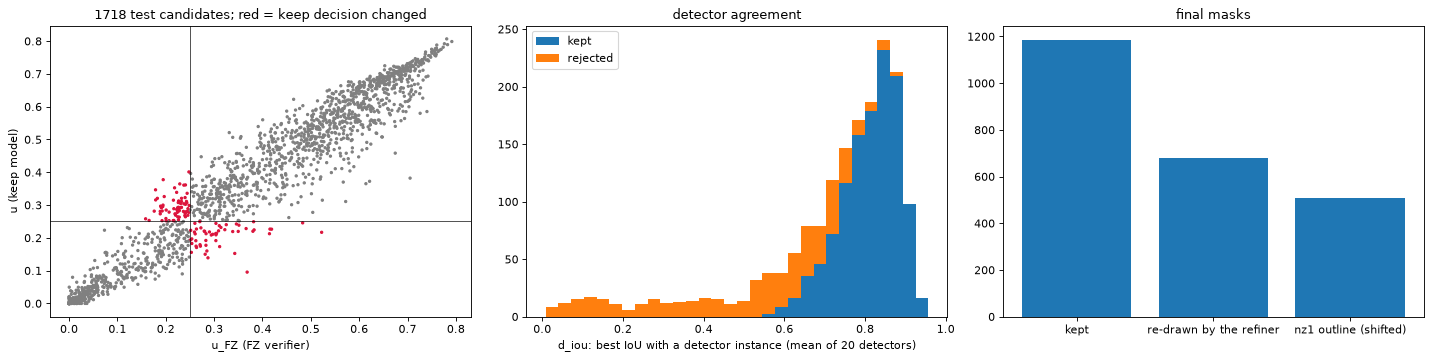

kept 1187 (FZ verifier: 1168); added 72, dropped 53; 678 of 1187 final masks re-drawn by the refiner


In [5]:
u = np.concatenate([f['u'] for f in frames.values()]); u_fz = np.concatenate([f['u_fz'] for f in frames.values()])
dv = np.concatenate([np.asarray(f['dv']).reshape(-1, 6) for f in frames.values()])
keep, keep_fz = u >= cfg['verifier']['tau'], u_fz >= cfg['verifier']['tau']
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ax[0].scatter(u_fz, u, s=4, c=np.where(keep != keep_fz, 'crimson', 'gray'))
ax[0].axhline(.25, color='k', lw=.6); ax[0].axvline(.25, color='k', lw=.6)
ax[0].set(xlabel='u_FZ (FZ verifier)', ylabel='u (keep model)', title=f'{len(u)} test candidates; red = keep decision changed')
ax[1].hist([dv[keep, 0], dv[~keep, 0]], 30, label=['kept', 'rejected'], stacked=True)
ax[1].set(xlabel='d_iou: best IoU with a detector instance (mean of 20 detectors)', title='detector agreement'); ax[1].legend()
redrawn = np.concatenate([f['redrawn'] for f in frames.values()]).astype(bool)
ax[2].bar(['kept', 're-drawn by the refiner', 'nz1 outline (shifted)'], [len(redrawn), redrawn.sum(), (~redrawn).sum()])
ax[2].set_title('final masks')
plt.tight_layout(); plt.show()
print(f'kept {keep.sum()} (FZ verifier: {keep_fz.sum()}); added {(keep & ~keep_fz).sum()}, dropped {(~keep & keep_fz).sum()}; '
      f'{redrawn.sum()} of {len(redrawn)} final masks re-drawn by the refiner')

## 5. What each stage does, on one test frame

The frame below is re-run in memory, stage by stage, with the same objects the pipeline uses. Panels: the fused map
and the context map; the detector instances of one model; the candidates with the keep decision; and, for a re-drawn
candidate, its nz1 outline, the refined mask and the shift.

20140707023654Uh: 17 candidates, 15 kept, 12 re-drawn; 38.1 s; same masks as the cached run: True


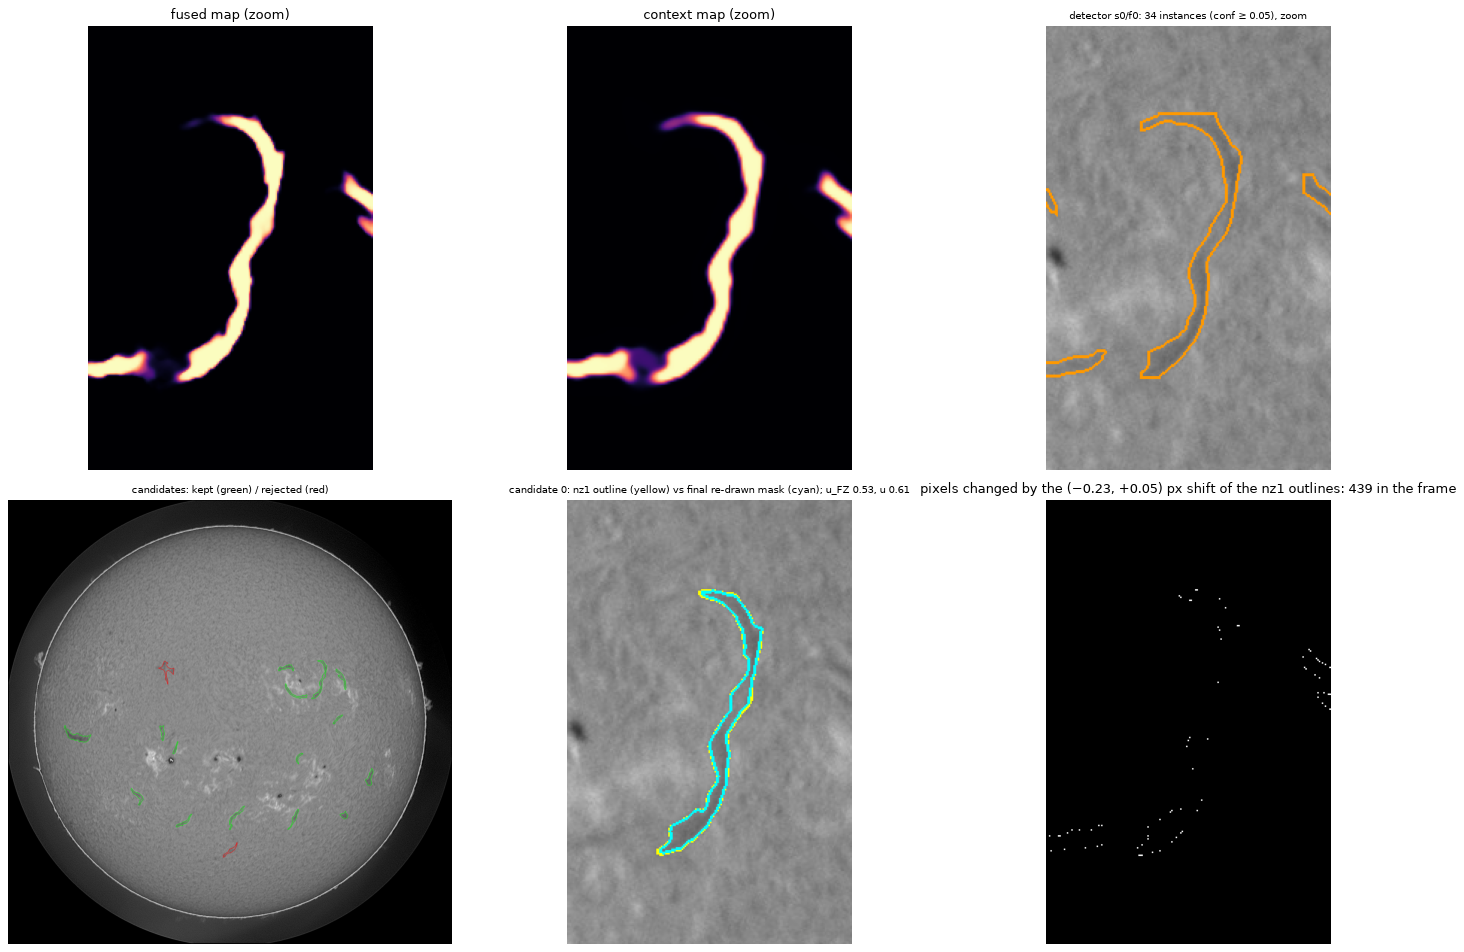

In [6]:
from filament_seg.candidates import candidate_labels
from filament_seg.postprocess import InstanceState, apply_steps
from filament_seg.pasteback import shifted_outlines
key = max(frames, key=lambda k: sum(frames[k]['redrawn']))
gray = read_gray(test_paths[key])
t0 = time.perf_counter()
maps = pipe.predictor(test_paths[key], keep_folds=True)
x = torch.from_numpy(maps['input'])[None, None].to(pipe.predictor.device)
context_map = pipe.context.maps(x, maps['cnx_folds'], maps['r34_folds'])
inst = pipe.detector.instances(gray)
res = pipe.process_final(key, gray, maps, detections=inst, context_map=context_map)
print(f'{key}: {len(res.u)} candidates, {res.keep.sum()} kept, {sum(res.extra["redrawn"])} re-drawn; '
      f'{time.perf_counter()-t0:.1f} s; same masks as the cached run: {res.rles == frames[key]["rles"]}')
labels = res.candidates
seeds = apply_steps(InstanceState(labels, np.ones(len(res.u), bool), maps['decode'][0], gray), cfg['postprocess']['steps'][:1])
j = max((jj for jj, r in zip(res.extra['candidates_of_masks'], res.extra['redrawn']) if r), key=lambda jj: (seeds.labels == jj+1).sum())
ys, xs = np.nonzero(seeds.labels == j+1); pad = 60
zoom = (slice(max(ys.min()-pad, 0), ys.max()+pad), slice(max(xs.min()-pad, 0), xs.max()+pad))
fig, ax = plt.subplots(2, 3, figsize=(19, 12))
ax[0, 0].imshow(maps['decode'][0][zoom], cmap='magma', vmin=0, vmax=1); ax[0, 0].set_title('fused map (zoom)')
ax[0, 1].imshow(context_map[0][zoom], cmap='magma', vmin=0, vmax=1); ax[0, 1].set_title('context map (zoom)')
det = np.zeros(gray.shape, np.int32)
for i, r in enumerate(inst[0]['rles'], 1):
    det[(cm.decode(r).astype(bool)) & (det == 0)] = i
viz.overlay(gray, [(det, (1, .6, 0))], ax[0, 2], f'detector s0/f0: {len(inst[0]["rles"])} instances (conf ≥ 0.05), zoom', crop=zoom)
kept = np.where(np.isin(labels, np.flatnonzero(res.keep)+1), labels, 0)
rej = np.where(np.isin(labels, np.flatnonzero(~res.keep)+1), labels, 0)
viz.overlay(gray, [(kept, (0, 1, 0)), (rej, (1, 0, 0))], ax[1, 0], 'candidates: kept (green) / rejected (red)')
final_j = res.instances == (res.extra['candidates_of_masks'].index(j)+1)
viz.overlay(gray, [((seeds.labels == j+1).astype(int), (1, 1, 0)), (final_j.astype(int), (0, 1, 1))], ax[1, 1],
            f'candidate {j}: nz1 outline (yellow) vs final re-drawn mask (cyan); u_FZ {res.extra["u_fz"][j]:.2f}, u {res.u[j]:.2f}', crop=zoom)
step = cfg['postprocess']['steps'][0]
moved = shifted_outlines(labels, maps['decode'][0], seeds.choice, cfg['postprocess']['steps'][-1]['shift'], step['levels'])
diff = (moved > 0) != (seeds.labels > 0)
ax[1, 2].imshow(diff[zoom], cmap='gray'); ax[1, 2].set_title(f'pixels changed by the (−0.23, +0.05) px shift of the nz1 outlines: {diff.sum()} in the frame')
for a in ax.ravel():
    a.axis('off')
plt.tight_layout(); plt.show()

## 6. Evaluation on held-out labelled frames: FZ_nz1 vs the final pipeline

The released models were refit on all 707 labelled frames, so no labelled frame is unseen by the full ensembles. For an
honest check we use the **142 frames of fold 0** and only models that never saw them:
- dense networks: ConvNeXt fold 0, specialist fold 0, ResNet34 fold 0, context network fold 0
- crop CNN fold 0, FZ verifier refit without fold 0 (`verifier_gbm_fz_without_fold0.pkl.gz`)
- detectors: the fold-0 model of each of the four seeds; keep model refit without fold 0 (`keep_gbm_y4_without_fold0.pkl.gz`)
- refiner fold 0

These are single-fold pipelines, so they understate the 5-model ensembles; the refiner in particular gains from the
ensemble (see METHODS.md). Both pipelines come from the same run: the FZ_nz1 output is the by-product described in
section 4. The metric follows the host's evaluation notebook: every annotator record is scored separately against the
same predictions, TP = pairs with IoU > 0.5, PQ pooled over records.

In [7]:
folds = json.loads(resolve(cfg['data']['folds']).read_text())['folds']
held = sorted(folds[0]['heldout_sources'])[:MAX_FRAMES]
held_paths = {k: train_paths[k] for k in held}
gt = load_ground_truth(data_path(cfg, 'train_annotations'), set(held))
print(f'{len(held)} frames, {sum(map(len, gt.values()))} annotator records, {sum(len(r) for v in gt.values() for _, r in v)} GT filaments')
del pipe
torch.cuda.empty_cache() if torch.cuda.is_available() else None
fold0 = Pipeline(cfg, segmenters=['cnx_fold0'], specialists=['spec_fold0'], voters=['r34_fold0'], crop_cnns=['crop_cnn_fz_fold0'],
                 gbm='verifier_gbm_fz_without_fold0.pkl.gz',
                 final_models={'context': ['l2_fold0'], 'detectors': [f'yolo_s{s}_f0' for s in range(4)], 'detector_groups': [1, 1, 1, 1],
                               'keep_gbm': 'keep_gbm_y4_without_fold0.pkl.gz', 'refiners': ['refiner_fold0']})
t0 = time.perf_counter()
held_frames = predict_frames(fold0, held_paths, OUT/'frames_heldout_fold0_final', log_every=71)
print(f'{(time.perf_counter()-t0)/60:.1f} min')
results = {'FZ_nz1': evaluate(gt, {k: f['fz_rles'] for k, f in held_frames.items()}),
           'final': evaluate(gt, {k: f['rles'] for k, f in held_frames.items()})}
for mode, r in results.items():
    o = r['overall']
    small = r['gt_area'] < 1000
    print(f"{mode:7s} PQ {o['pq']:.4f}  SQ {o['sq']:.4f}  RQ {o['rq']:.4f}  TP {o['tp']:4d}  FP {o['fp']:4d}  FN {o['fn']:4d}  "
          f"recall < 1000 px {r['gt_hit'][small].mean():.3f}, >= 1000 px {r['gt_hit'][~small].mean():.3f}")
print(f"final - FZ_nz1 on these frames: {results['final']['overall']['pq']-results['FZ_nz1']['overall']['pq']:+.4f}")

142 frames, 236 annotator records, 1633 GT filaments


71/142 frames (0 computed now, 71 from the cache), 0 s elapsed


142/142 frames (0 computed now, 142 from the cache), 0 s elapsed


0.0 min
FZ_nz1  PQ 0.4820  SQ 0.6878  RQ 0.7008  TP 1101  FP  408  FN  532  recall < 1000 px 0.596, >= 1000 px 0.732
final   PQ 0.4867  SQ 0.6910  RQ 0.7043  TP 1085  FP  363  FN  548  recall < 1000 px 0.573, >= 1000 px 0.732
final - FZ_nz1 on these frames: +0.0047


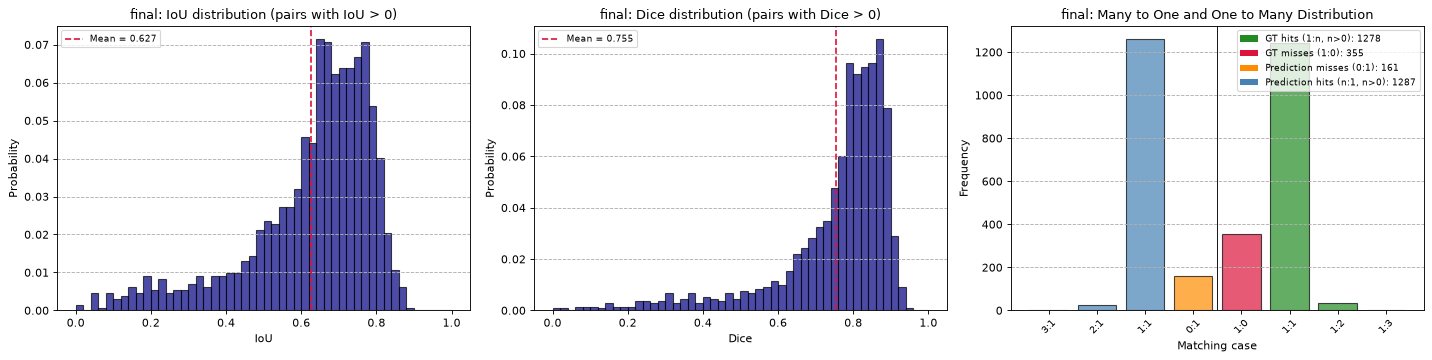

FZ_nz1  GT -> #overlapping predictions: {0: 324, 1: 1258, 2: 47, 3: 3, 4: 1} | prediction -> #overlapping GT: {0: 171, 1: 1312, 2: 25, 3: 1}
final   GT -> #overlapping predictions: {0: 355, 1: 1242, 2: 34, 3: 2} | prediction -> #overlapping GT: {0: 161, 1: 1260, 2: 25, 3: 2}


In [8]:
final = results['final']
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
viz.plot_distribution(final['positive_ious'], 'final: IoU distribution (pairs with IoU > 0)', 'IoU', ax[0])
viz.plot_distribution(final['positive_dices'], 'final: Dice distribution (pairs with Dice > 0)', 'Dice', ax[1])
viz.plot_relations(final['gt_degree'], final['pred_degree'], ax[2], 'final: Many to One and One to Many Distribution')
plt.tight_layout(); plt.show()
for mode, r in results.items():
    print(f'{mode:7s} GT -> #overlapping predictions:', dict(sorted(r['gt_degree'].items())),
          '| prediction -> #overlapping GT:', dict(sorted(r['pred_degree'].items())))

## 7. Overlays

Held-out frames: every annotator's filaments (one colour per annotator), FZ_nz1 (white) and the final pipeline (cyan,
drawn on top, so white shows only where the two differ). Then two test frames with the final predictions only (no
labels exist for them). Each row shows the full frame and a zoom.

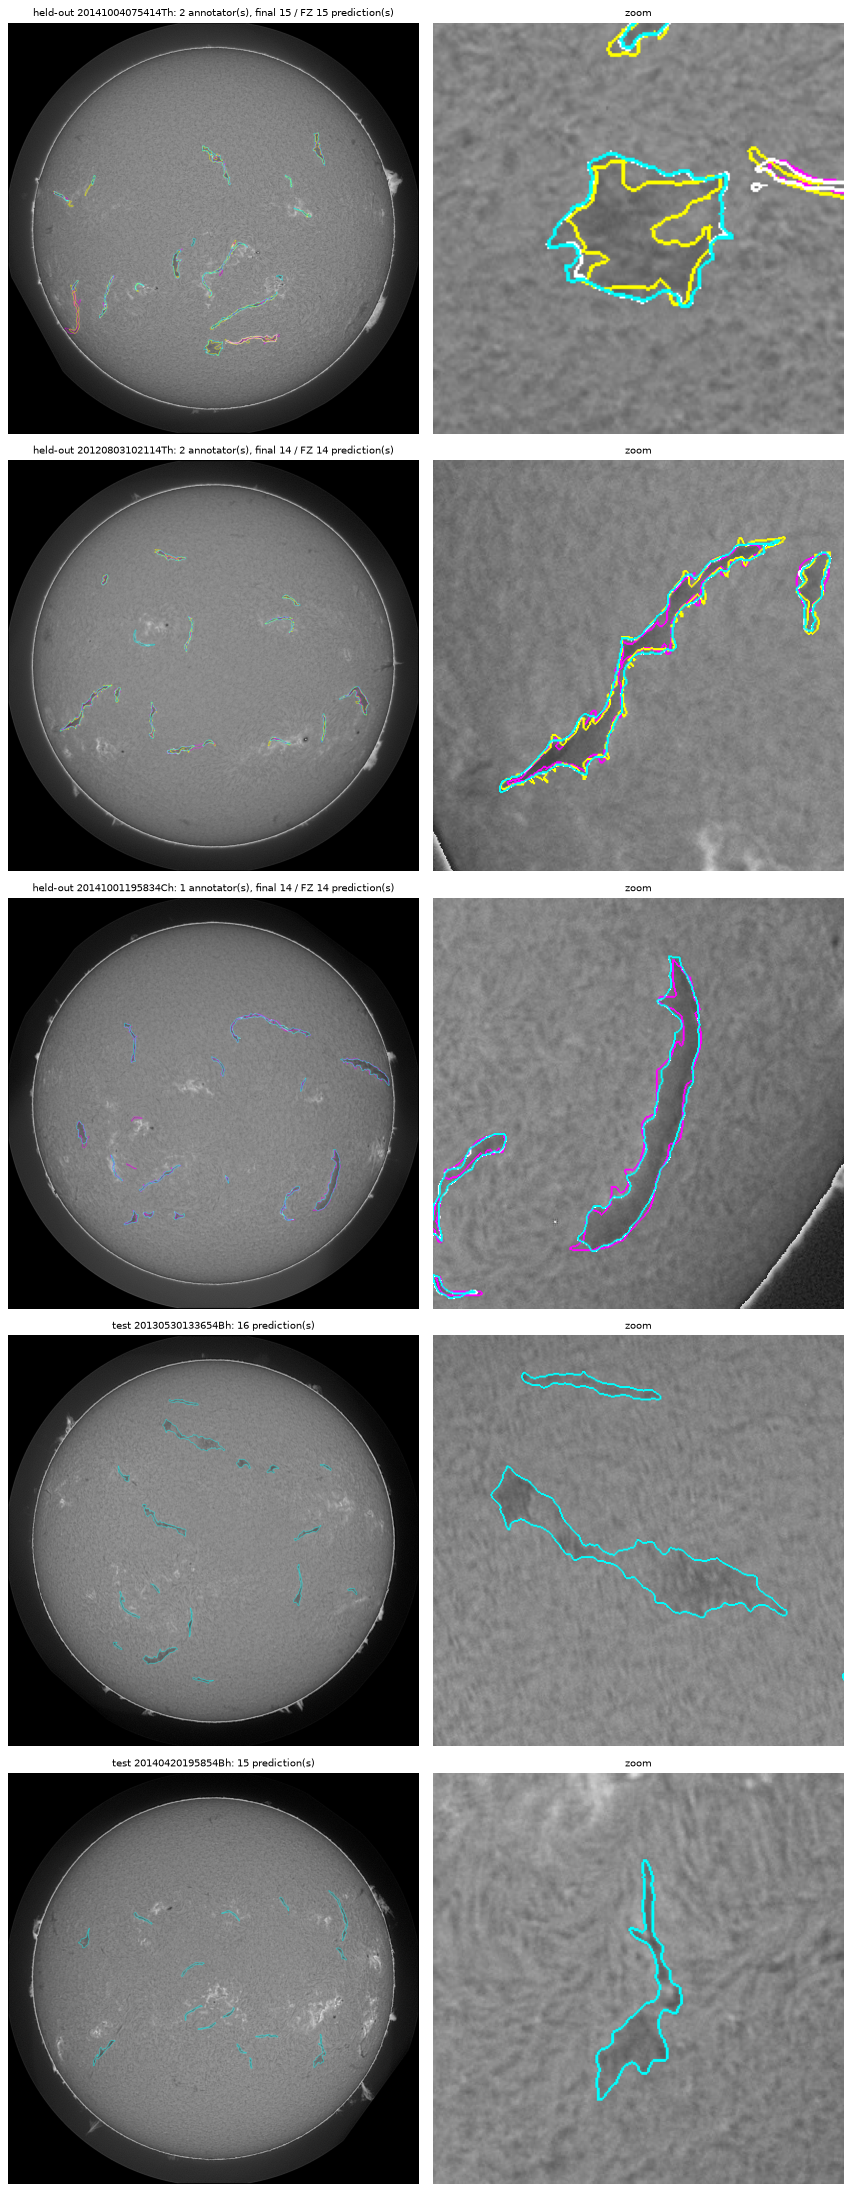

In [9]:
def rles_to_labels(rles):
    lab = np.zeros((2048, 2048), np.int32)
    for i, r in enumerate(rles, 1):
        lab[cm.decode({'size': [2048, 2048], 'counts': r.encode() if isinstance(r, str) else r}).astype(bool)] = i
    return lab

def zoom_box(lab, pad=60):
    if lab.max() == 0:
        return (slice(512, 1536), slice(512, 1536))
    big = np.argmax(np.bincount(lab.ravel())[1:])+1
    ys, xs = np.nonzero(lab == big)
    cy, cx, h = (ys.min()+ys.max())//2, (xs.min()+xs.max())//2, max(np.ptp(ys), np.ptp(xs))//2+pad
    return (slice(max(cy-h, 0), cy+h), slice(max(cx-h, 0), cx+h))

colours = [(1, 0, 1), (1, 1, 0), (1, .5, 0), (0, 1, 0)]
changed = sorted(held, key=lambda k: -sum(a != b for a, b in zip(held_frames[k]['rles'], held_frames[k]['fz_rles'])))[:3]
fig, ax = plt.subplots(len(changed)+2, 2, figsize=(11, 5.5*(len(changed)+2)))
for row, k in enumerate(changed):
    g = read_gray(train_paths[k]); fin = rles_to_labels(held_frames[k]['rles']); fzl = rles_to_labels(held_frames[k]['fz_rles'])
    layers = [(rles_to_labels([r['counts'] for r in rl]), colours[i % 4]) for i, (_, rl) in enumerate(gt[k])] + [(fzl, (1, 1, 1)), (fin, (0, 1, 1))]
    viz.overlay(g, layers, ax[row, 0], f'held-out {k}: {len(gt[k])} annotator(s), final {fin.max()} / FZ {fzl.max()} prediction(s)')
    viz.overlay(g, layers, ax[row, 1], 'zoom', crop=zoom_box(fin))
for row, k in enumerate(sorted(frames, key=lambda k: -len(frames[k]['rles']))[:2], len(changed)):
    g = read_gray(test_paths[k]); pred = rles_to_labels(frames[k]['rles'])
    viz.overlay(g, [(pred, (0, 1, 1))], ax[row, 0], f'test {k}: {pred.max()} prediction(s)')
    viz.overlay(g, [(pred, (0, 1, 1))], ax[row, 1], 'zoom', crop=zoom_box(pred))
plt.tight_layout(); plt.show()

## Notes

- **Weights.** Dense U-Nets: fp32 safetensors shards (each < 95 MB). Crop CNNs, context networks and refiners run only
  under bf16 autocast, so their conv/linear tensors are stored in bf16, which is exactly what autocast computes with.
  YOLO detectors: the Ultralytics checkpoints as trained. GBMs: gzip pickles (scikit-learn 1.9.1). Every file is
  checked against `weights/manifest.json` when it is loaded.
- **Data rules.** Training used only the official training annotations: no external labels and no other GONG frames.
  Inference reads nothing but the test image itself.
- **Hardware and time** of the saved run: printed in sections 1 and 4; the README has the same numbers.

- **This saved run.** One NVIDIA RTX 5090 (32 GB) with 32 vCPUs, Linux, Python 3.13.5, PyTorch 2.11.0 (CUDA 12.8
  build), the other packages as pinned in `requirements.txt`. The notebook was executed twice. The first execution
  computed every frame: the 180 test frames in 76.2 minutes (median 24.7 s per frame: dense networks 9.0 s,
  detectors 13.0 s, of which most is the CPU-side computation of the agreement columns, everything else about 2.7 s),
  the 142 held-out frames in 10.2 minutes, 87 minutes for the whole notebook. The second execution, after a change
  to how section 4 pairs the masks of the two files (by IoU instead of by row), read those frames from the per-frame
  cache in `outputs/`; the timings printed in section 4 are the ones recorded when each frame was computed.
- **Why the reproduced file is not byte-identical.** The submitted file was made from intermediate outputs computed on
  other GPUs with other library versions. Fed with those stored outputs, this code reproduces the submitted file byte
  for byte (README, "Results"). Recomputed on this GPU, the maps differ in single float16 steps, which moves single
  pixels across a threshold: every candidate gets the same keep decision, and the masks that differ change by a few
  pixels (section 4).